<a href="https://colab.research.google.com/github/ClaraMacena/RNA-e-Deep-Learning---CESAR-School-2026.01-A/blob/Atividade-2/atividade_regressao_california_housing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regressão linear múltipla com dados reais: preço de casas na Califórnia

O problema: dadas 8 características de um quarteirão da Califórnia (censo de 1990), prever o valor mediano das casas dessa região. As entradas são $x_1, \dots, x_8$ e a saída $y$ é MedHouseVal, em centenas de milhares de dólares (por exemplo, $y = 2{,}5$ significa US\$ 250 mil). O modelo é a mesma reta do 2.6, agora com um peso por variável:

$$\hat{y} = w_0 + w_1 x_1 + w_2 x_2 + \dots + w_8 x_8 = w_0 + \mathbf{w}^T \mathbf{x}$$

com $w_0$ = bias e $w_1, \dots, w_8$ = pesos.

## Importação das bibliotecas

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch
from torch import nn, optim

torch.manual_seed(1234)
np.random.seed(1234)

## Dados

Fonte: *California Housing*, distribuído pelo scikit-learn (derivado do censo americano de 1990).

In [3]:
dados = fetch_california_housing(as_frame=True)
X, y = dados.data, dados.target   # 20.640 quarteirões, 8 variáveis; y em centenas de milhares de dólares

feature_names = list(X.columns)   # as 8 variáveis de entrada
df = X.assign(MedHouseVal=y)      # tabela única, só para a análise
print('shape:', df.shape)
print('valores ausentes:', int(df.isna().sum().sum()))
df.head()

shape: (20640, 9)
valores ausentes: 0


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


### Análise dos dados

O que cada variável significa:

| # | Coluna | Significado |
|---|---|---|
| 1 | `MedInc` | renda mediana da região (dezenas de milhares de US\$) |
| 2 | `HouseAge` | idade mediana das casas (anos) |
| 3 | `AveRooms` | média de cômodos por domicílio |
| 4 | `AveBedrms` | média de quartos por domicílio |
| 5 | `Population` | população da região |
| 6 | `AveOccup` | média de moradores por domicílio |
| 7 | `Latitude` | latitude |
| 8 | `Longitude` | longitude |
| saída | `MedHouseVal` | valor mediano das casas, em centenas de milhares de US\$ |

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


In [5]:
# correlação linear de cada variável com o preço
df.corr()['MedHouseVal'].drop('MedHouseVal').sort_values().round(2).to_frame('correlação com o preço')

,correlação com o preço
Latitude,-0.14
AveBedrms,-0.05
Longitude,-0.05
Population,-0.02
AveOccup,-0.02
HouseAge,0.11
AveRooms,0.15
MedInc,0.69


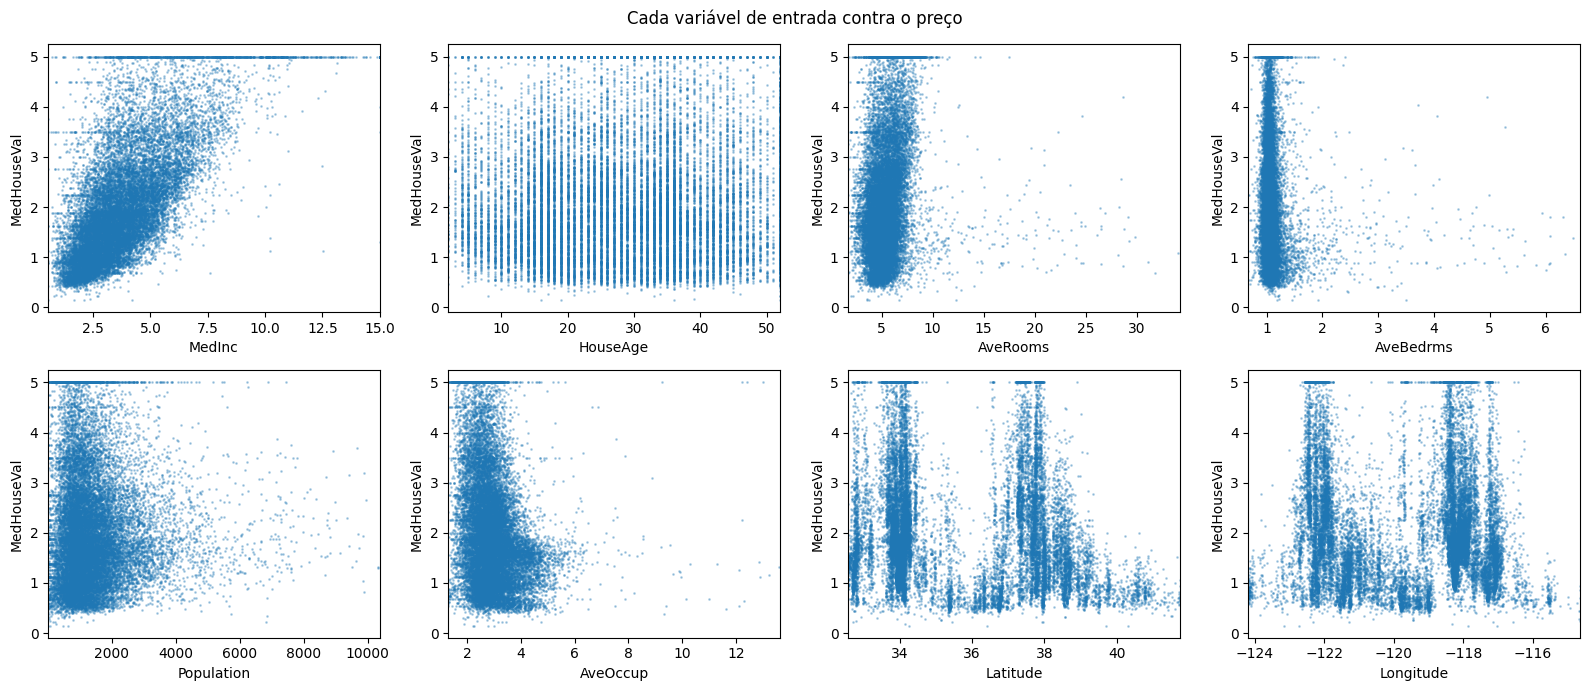

In [6]:
# gráficos de dispersão: cada variável de entrada contra o preço
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, name in zip(axes.ravel(), feature_names):
    ax.scatter(df[name], df['MedHouseVal'], s=1, alpha=0.3)
    # corta 0,1% de cada ponta do eixo x só para o gráfico ficar legível (há valores extremos)
    ax.set_xlim(df[name].quantile(0.001), df[name].quantile(0.999))
    ax.set_xlabel(name)
    ax.set_ylabel('MedHouseVal')
plt.suptitle('Cada variável de entrada contra o preço')
plt.tight_layout()
plt.show()

Pontos observados:

- São 20 640 linhas e nenhum valor ausente.
- As variáveis têm escalas muito diferentes (Population na casa dos milhares,AveBedrms perto de 1, Latitude entre ~32 e ~42): isso justifica a padronização.
- AveRooms, AveBedrms, AveOccup e Population têm valores extremos (máximos muito acima do 75º percentil no describe()), por exemplo regiões com poucos moradores e muitas casas vazias.
- O preço tem um teto em 5,0 (US\$ 500 mil): há uma fileira de pontos empilhados nesse valor, truncados na coleta.
- MedInc é, de longe, a variável mais relacionada ao preço (correlação em torno de 0,69; no gráfico, tendência crescente com muita dispersão). As outras têm correlação linear fraca com o preço (no máximo cerca de 0,15 em módulo). Latitude e Longitude aparecem em "faixas" no gráfico (regiões caras e baratas), um padrão que uma reta capta mal.
- Algumas variáveis são fortemente correlacionadas entre si: Latitude e Longitude, e AveRooms e AveBedrms. Isso volta na leitura dos pesos.

### Treino × validação × teste

Os parâmetros são ajustados só com o conjunto de treino. O de validação fica de fora do treino e serve para acompanhar o custo em dados que o modelo não viu. O de teste só é usado uma vez, no final, para medir o desempenho em dados novos.

Dois sorteios com train_test_split(..., random_state=42): primeiro 70% para treino e 30% para o resto; depois o resto é dividido ao meio, em validação (15%) e teste (15%). random_state fixa o sorteio, para que a divisão seja sempre a mesma.

In [7]:
x_raw = X.to_numpy()                     # (20640, 8)
y_raw = y.to_numpy().reshape(-1, 1)      # (20640, 1)

x_train_raw, x_temp_raw, y_train_raw, y_temp_raw = train_test_split(
    x_raw, y_raw, test_size=0.30, random_state=42)
x_val_raw, x_test_raw, y_val_raw, y_test_raw = train_test_split(
    x_temp_raw, y_temp_raw, test_size=0.50, random_state=42)

print('treino:    ', x_train_raw.shape)
print('validação: ', x_val_raw.shape)
print('teste:     ', x_test_raw.shape)

treino:     (14448, 8)
validação:  (3096, 8)
teste:      (3096, 8)


### Normalização

As variáveis têm escalas muito diferentes (`MedInc` fica entre 0 e 15; `Population`, entre 3 e 35 mil). Com escalas assim, o gradiente descendente precisaria de uma taxa de aprendizado minúscula. Padronizamos cada variável (z-score):

$$z_j = \frac{x_j - \mu_j}{\sigma_j}$$

em que $\mu_j$ e $\sigma_j$ são a média e o desvio padrão **da coluna $j$**. O `StandardScaler` faz essa conta coluna por coluna: com `x_train_raw` de shape (14448, 8), ele guarda 8 médias e 8 desvios. `fit` calcula $\mu$ e $\sigma$, `transform` aplica a fórmula e `inverse_transform` desfaz. A saída $y$ tem um scaler próprio.

$\mu$ e $\sigma$ são calculados **só no treino** e depois aplicados à validação e ao teste. Se fossem calculados com todos os dados, informação da validação e do teste entraria no treino (vazamento de dados), e eles deixariam de representar dados novos.

In [8]:
x_scaler = StandardScaler().fit(x_train_raw)
y_scaler = StandardScaler().fit(y_train_raw)

# tensores float32 (sem requires_grad: são dados, não parâmetros)
x_train = torch.from_numpy(x_scaler.transform(x_train_raw)).float()
y_train = torch.from_numpy(y_scaler.transform(y_train_raw)).float()
x_val = torch.from_numpy(x_scaler.transform(x_val_raw)).float()
y_val = torch.from_numpy(y_scaler.transform(y_val_raw)).float()
x_test = torch.from_numpy(x_scaler.transform(x_test_raw)).float()
y_test = torch.from_numpy(y_scaler.transform(y_test_raw)).float()

print('x_train:', x_train.shape, ' y_train:', y_train.shape)
print('x_val:  ', x_val.shape, ' y_val:  ', y_val.shape)
print('x_test: ', x_test.shape, ' y_test: ', y_test.shape)
print('média por coluna (treino): ', x_train.mean(dim=0))
print('desvio por coluna (treino):', x_train.std(dim=0, unbiased=False))

x_train: torch.Size([14448, 8])  y_train: torch.Size([14448, 1])
x_val:   torch.Size([3096, 8])  y_val:   torch.Size([3096, 1])
x_test:  torch.Size([3096, 8])  y_test:  torch.Size([3096, 1])
média por coluna (treino):  tensor([-7.2608e-10, -6.3367e-09,  1.0561e-09,  5.2806e-10,  1.3201e-10,
        -5.2806e-10, -3.6964e-09,  0.0000e+00])
desvio por coluna (treino): tensor([1., 1., 1., 1., 1., 1., 1., 1.])


## Modelo

`nn.Linear(8, 1)` tem `bias=True` por padrão e calcula $\hat{y} = \mathbf{w}^T\mathbf{x} + w_0$:

- `model.weight`, shape **(1, 8)**, guarda os pesos $w_1, \dots, w_8$ (um por variável, na ordem de `feature_names`);
- `model.bias`, shape (1,), é o bias $w_0$.

São 9 parâmetros no total. Como no 2.6, não é preciso a coluna de uns: a camada soma o bias. Usamos a inicialização padrão do `nn.Linear`.

In [9]:
model = nn.Linear(8, 1)
print('weight (w1..w8):', model.weight)
print('bias (w0):      ', model.bias)
print('shapes:', model.weight.shape, model.bias.shape)

weight (w1..w8): Parameter containing:
tensor([[-0.3331, -0.0694, -0.1698, -0.0943, -0.3123,  0.1419, -0.3169, -0.0225]],
       requires_grad=True)
bias (w0):       Parameter containing:
tensor([0.1229], requires_grad=True)
shapes: torch.Size([1, 8]) torch.Size([1])


### Testando o predict da rede

In [10]:
model(torch.ones(5, 8))

tensor([[-1.0536],
        [-1.0536],
        [-1.0536],
        [-1.0536],
        [-1.0536]], grad_fn=<AddmmBackward0>)

In [11]:
model(x_train[:3])

tensor([[0.3319],
        [0.9249],
        [0.4498]], grad_fn=<AddmmBackward0>)

## Treinamento

### Função de custo e otimizador

`nn.MSELoss` e `optim.SGD`, como no 2.6, com duas mudanças nos hiperparâmetros:

- `lr = 0.1` (no 2.6 era 0,3). Com variáveis padronizadas, o gradiente descendente é estável se $\text{lr} < 1/\lambda_{max}$, em que $\lambda_{max}$ é o maior autovalor da matriz de correlação das variáveis. Como $\lambda_{max} \le 8$ (o número de variáveis), qualquer $\text{lr} < 0{,}125$ é seguro.
- `n_epochs = 1000` (no 2.6 eram 120). Variáveis correlacionadas (por exemplo `Latitude` e `Longitude`) deixam o custo "achatado" em algumas direções, e o gradiente descendente demora mais para percorrê-las.

In [12]:
lr = 0.1
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=lr)   # atualiza weight (8 pesos) e bias

### Funções de treino e de validação

Exatamente as mesmas do 2.6: o código de uma época não depende do número de variáveis, porque `nn.Linear`, `criterion` e `optimizer` cuidam dos shapes.

- `train_epoch` faz um passo de gradiente descendente com todo o conjunto de treino (as 14 448 amostras de uma vez; aqui uma época é uma iteração) e devolve o custo;
- `validate_epoch` só calcula o custo na validação, sem atualizar nada (`model.eval()` e `torch.no_grad()`).

In [13]:
def train_epoch(model, optimizer, criterion, x_train, y_train):
    model.train()            # modo de treino
    optimizer.zero_grad()

    # forward
    y_pred = model(x_train)
    loss = criterion(y_pred, y_train)

    # backward e otimizador
    loss.backward()
    optimizer.step()

    return loss.item()       # custo como número Python

In [14]:
def validate_epoch(model, criterion, x_val, y_val):
    model.eval()             # modo de avaliação
    with torch.no_grad():    # sem grafo do autograd: não haverá backward
        y_pred = model(x_val)
        loss = criterion(y_pred, y_val)
    return loss.item()

### Laço de treinamento

A cada época: um passo de treino e a medida na validação. Como no 2.6, `train_loss` é medido no forward, antes do `step()` daquela época, e `val_loss` depois dele. O conjunto de teste **não** participa do laço.

In [15]:
n_epochs = 1000
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    train_loss = train_epoch(model, optimizer, criterion, x_train, y_train)
    train_losses.append(train_loss)

    val_loss = validate_epoch(model, criterion, x_val, y_val)
    val_losses.append(val_loss)

    if (epoch + 1) % 100 == 0:
        print(f'Epoch[{epoch + 1}/{n_epochs}], Train Loss: {train_loss:.6f}, Val Loss: {val_loss:.6f}')

Epoch[100/1000], Train Loss: 0.393754, Val Loss: 0.406560
Epoch[200/1000], Train Loss: 0.390795, Val Loss: 0.403884
Epoch[300/1000], Train Loss: 0.390663, Val Loss: 0.403760
Epoch[400/1000], Train Loss: 0.390655, Val Loss: 0.403742
Epoch[500/1000], Train Loss: 0.390654, Val Loss: 0.403735
Epoch[600/1000], Train Loss: 0.390654, Val Loss: 0.403732
Epoch[700/1000], Train Loss: 0.390654, Val Loss: 0.403731
Epoch[800/1000], Train Loss: 0.390654, Val Loss: 0.403730
Epoch[900/1000], Train Loss: 0.390654, Val Loss: 0.403730
Epoch[1000/1000], Train Loss: 0.390654, Val Loss: 0.403730


## Avaliação

### Curvas de custo de treino e de validação

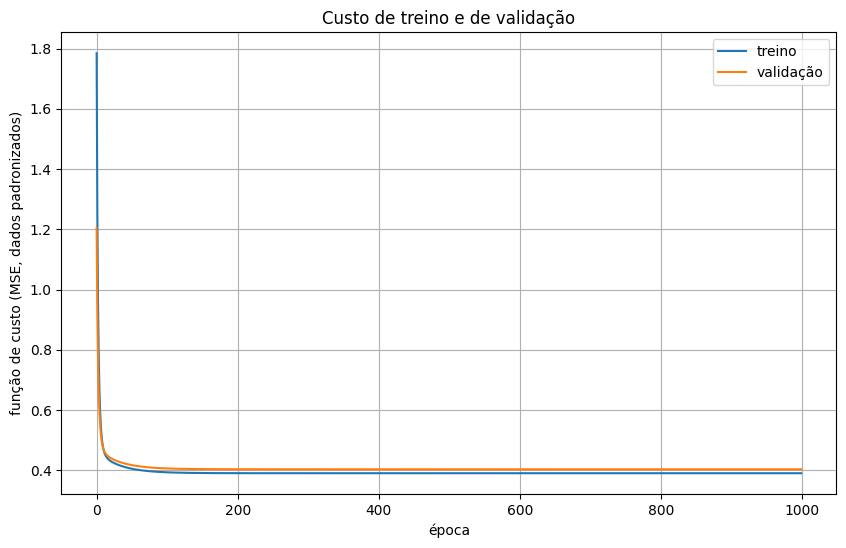

In [16]:
plt.figure(figsize=(10, 6))
plt.plot(range(n_epochs), train_losses, label='treino')
plt.plot(range(n_epochs), val_losses, label='validação')
plt.xlabel('época')
plt.ylabel('função de custo (MSE, dados padronizados)')
plt.title('Custo de treino e de validação')
plt.legend()
plt.grid(True)
plt.show()

As duas curvas caem rápido no começo e depois **estabilizam, praticamente coladas**: o custo de validação acompanha o de treino. Não há *overfitting*; o custo estabiliza num patamar relativamente alto porque uma reta no espaço das 8 variáveis é um modelo simples demais para este problema (*underfitting*), e não por falta de épocas.

### RMSE no teste, em dólares, contra um baseline

Agora, uma única vez, usamos o conjunto de teste. O MSE do treino está na escala padronizada, difícil de interpretar; calculamos a raiz do erro quadrático médio (RMSE) **em dólares**:

$$\text{RMSE} = \sqrt{\frac{1}{M_{teste}}\sum_{i=1}^{M_{teste}}\left(\hat{y}^{(i)} - y^{(i)}\right)^2}$$

Usamos `y_scaler.inverse_transform` para levar as previsões de volta à escala original (centenas de milhares de US\$) e multiplicamos por 100 000.

O **baseline** é o modelo mais simples possível: prever, para qualquer quarteirão, o preço médio do **treino**. Se o modelo treinado não for melhor que isso, as 8 variáveis não estariam ajudando.

In [17]:
model.eval()
with torch.no_grad():
    y_pred_test = model(x_test)
y_pred_test_raw = y_scaler.inverse_transform(y_pred_test.numpy())   # de volta à escala original

# RMSE em dólares (a escala original é em centenas de milhares de US$)
rmse_test = np.sqrt(np.mean((y_pred_test_raw - y_test_raw) ** 2)) * 100_000
# baseline: prevê sempre a média do treino
rmse_base = np.sqrt(np.mean((y_train_raw.mean() - y_test_raw) ** 2)) * 100_000
# R² no teste: fração da variância do preço explicada pelo modelo
r2_test = 1 - np.sum((y_pred_test_raw - y_test_raw) ** 2) / np.sum((y_test_raw - y_test_raw.mean()) ** 2)

print(f'RMSE no teste (modelo):    US$ {rmse_test:,.0f}')
print(f'RMSE no teste (baseline):  US$ {rmse_base:,.0f}')
print(f'redução do erro:           {100 * (1 - rmse_test / rmse_base):.1f}%')
print(f'preço médio (treino):      US$ {y_train_raw.mean() * 100_000:,.0f}')
print(f'R² no teste:               {r2_test:.3f}')

RMSE no teste (modelo):    US$ 72,129
RMSE no teste (baseline):  US$ 114,992
redução do erro:           37.3%
preço médio (treino):      US$ 206,924
R² no teste:               0.607


Com 8 variáveis não dá para desenhar "a reta" sobre os dados, como no 2.6. Em vez disso, comparamos, para cada amostra do teste, o preço previsto com o preço real. Se o modelo fosse perfeito, todos os pontos ficariam sobre a diagonal $\hat{y} = y$.

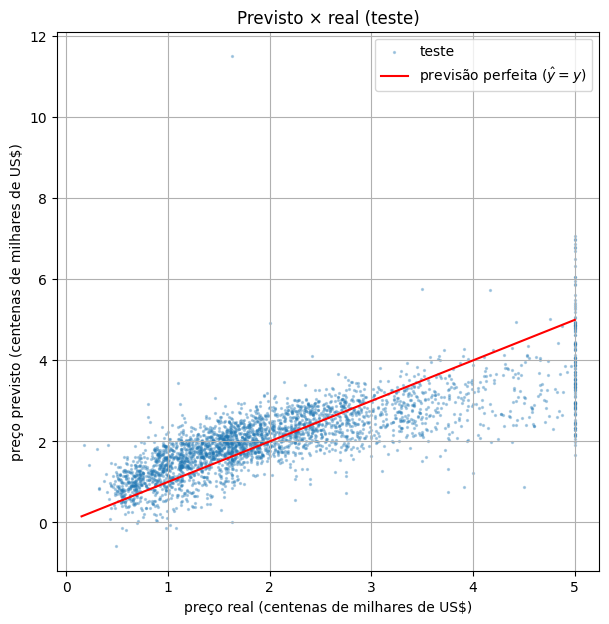

In [18]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test_raw, y_pred_test_raw, s=2, alpha=0.3, label='teste')
lims = [y_raw.min(), y_raw.max()]
plt.plot(lims, lims, 'r-', label='previsão perfeita ($\\hat{y} = y$)')
plt.xlabel('preço real (centenas de milhares de US$)')
plt.ylabel('preço previsto (centenas de milhares de US$)')
plt.title('Previsto × real (teste)')
plt.legend()
plt.grid(True)
plt.show()

O modelo erra, em média, algumas dezenas de milhares de dólares (valor impresso acima), bem menos que o baseline, mas ainda com muita dispersão em torno da diagonal. A faixa horizontal em y = 5 são os preços truncados no teto da base, onde o modelo erra sistematicamente.

### Parâmetros treinados (os 8 pesos)

Os pesos estão na escala padronizada: $w_j$ é a variação do preço (em desvios padrão do preço) para **+1 desvio padrão** da variável $j$, mantendo as outras fixas. Para ler em dólares, multiplicamos pelo desvio padrão do preço (do treino) e por 100 000. Também conferimos o treino com a solução analítica (mínimos quadrados): se o gradiente descendente convergiu, as diferenças devem ser pequenas.

In [19]:
w = model.weight.detach().numpy().ravel()                  # os 8 pesos (escala padronizada)
w_dolar = w * y_scaler.scale_[0] * 100_000                 # US$ por +1 desvio padrão da variável

pesos = pd.DataFrame({'peso (padronizado)': w,
                      'US$ por +1 desvio padrão': w_dolar},
                     index=feature_names).sort_values('peso (padronizado)')
print(f'w0 (bias): {model.bias.item():+.4f}')
print(f'MSE final  treino: {train_losses[-1]:.4f}   validação: {val_losses[-1]:.4f}')
pesos.round(3)

w0 (bias): +0.0000
MSE final  treino: 0.3907   validação: 0.4037


,peso (padronizado),US$ por +1 desvio padrão
Latitude,-0.772,-89384.693
Longitude,-0.750,-86860.849
AveRooms,-0.259,-29956.547
AveOccup,-0.036,-4169.819
Population,-0.001,-88.426
HouseAge,0.106,12212.004
AveBedrms,0.301,34841.541
MedInc,0.734,84922.553


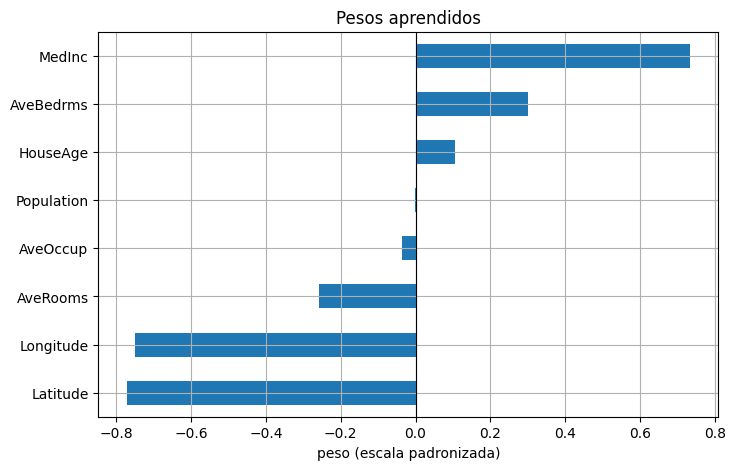

maior diferença |treinado - analítico|: 7.5335636523510274e-06


In [20]:
pesos['peso (padronizado)'].plot.barh(figsize=(8, 5), grid=True)
plt.axvline(0, color='k', linewidth=0.8)
plt.xlabel('peso (escala padronizada)')
plt.title('Pesos aprendidos')
plt.show()

# conferência com a solução analítica (mínimos quadrados) nos dados de treino
A_train = np.hstack([np.ones((x_train.shape[0], 1)), x_train.numpy()])
w_analitico = np.linalg.lstsq(A_train, y_train.numpy(), rcond=None)[0].ravel()   # [w0, w1..w8]
w_treinado = np.concatenate([model.bias.detach().numpy(), w])
print('maior diferença |treinado - analítico|:', np.abs(w_treinado - w_analitico).max())

**Quais variáveis mais aumentam e quais mais diminuem o preço previsto?**

Os valores abaixo são aproximados; confira na tabela acima.

*Aumentam o preço:*
- `MedInc` é, de longe, o maior peso positivo: +1 desvio padrão na renda mediana (cerca de US\$ 19 mil) eleva o preço previsto em algo como **US\$ 80 mil**, com as outras variáveis fixas.
- Depois vêm `AveBedrms` (algo como +US\$ 30 mil) e `HouseAge` (cerca de +US\$ 10 mil).

*Diminuem o preço:*
- `Latitude` e `Longitude` são os maiores pesos negativos (cada um em torno de **−US\$ 90 mil** por desvio padrão): na Califórnia, regiões mais ao norte e mais a leste (para o interior) têm, em média, preços menores. Os dois juntos funcionam como um "mapa" aproximado, com o sul e o litoral mais caros.
- Em seguida `AveRooms` (cerca de −US\$ 25 mil) e `AveOccup` (pequeno).
- `Population` fica praticamente em zero: depois de considerar as outras variáveis, quase não acrescenta nada.

*Cuidado com a leitura:* `Latitude` e `Longitude` são fortemente correlacionadas entre si (≈ −0,92), e `AveRooms` e `AveBedrms` também (≈ 0,85). Com entradas correlacionadas, o peso de cada uma depende das outras, e os sinais podem parecer estranhos (mais quartos aumentando o preço, mais cômodos diminuindo). O par `AveRooms`/`AveBedrms` deve ser lido em conjunto, e os pesos descrevem associações do modelo, não causas. Note também que `Latitude` tem correlação linear fraca com o preço (≈ −0,14), mas um peso grande: o efeito da localização só aparece quando latitude e longitude são consideradas juntas.

**Por que só faz sentido comparar os pesos entre si porque as entradas foram padronizadas?**

Um peso mede "quanto o preço muda por **unidade** da variável", e as unidades são diferentes: `Population` está em pessoas (o peso seria minúsculo, da ordem de $10^{-6}$ por pessoa), `AveBedrms` em quartos, `MedInc` em dezenas de milhares de dólares, `Latitude` em graus. Sem padronizar, um peso pequeno pode vir só de uma variável com escala grande, e não de um efeito pequeno; comparar os 8 números seria comparar unidades diferentes.

Com a padronização, todas as entradas têm média 0 e desvio padrão 1, e cada peso passa a significar "efeito no preço de aumentar **1 desvio padrão** dessa variável". Todos os pesos ficam na mesma régua, e $|w_j|$ indica a importância relativa de cada variável (com a ressalva das variáveis correlacionadas).

## Conclusão

**O modelo é bom o suficiente?** Em parte. Em relação ao baseline, ele reduz o erro de forma clara: o RMSE no teste é da ordem de US\$ 70 mil, contra cerca de US\$ 115 mil do baseline (algo como 35% a 40% menos), e o R² fica em torno de 0,6. As 8 variáveis trazem informação real. Por outro lado, um erro típico de ~ US\$ 70 mil é cerca de um terço do preço médio (~US\$ 207 mil), o que é grande demais para estimar o preço de um imóvel. Serve como um primeiro modelo e uma referência para comparar os próximos. As curvas de treino e de validação ficam coladas, então o limite é a capacidade do modelo (underfitting), e não overfitting.

**O que eu tentaria para melhorar:**

1. **Relações não lineares:** adicionar features polinomiais e interações, ou usar uma rede com camadas escondidas (*MLP*), já que o preço depende de forma não linear da renda e da localização.
2. **Melhor representação da localização:** Latitude e Longitude entram como reta, mas o efeito é por regiões; criar a distância ao litoral e às grandes cidades, ou agrupar as coordenadas (*clusters*).
3. **Engenharia de features e outliers:** razões como quartos/cômodos, log de Population e AveOccup (caudas longas) e tratamento dos valores extremos.
4. **Teto de US\$ 500 mil:** remover ou tratar os preços truncados, que distorcem o ajuste.
5. **Outros modelos:** árvores, *random forest* e *gradient boosting* costumam errar bem menos nessa base.